In [23]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import ExponentialLR

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output

from datasets import load_dataset
from transformers import AutoTokenizer
from transformers import DataCollatorWithPadding
from transformers import AutoModel

import gc
from collections import defaultdict
import typing as tp
import numpy as np
from scipy.optimize import linprog
import copy
import pickle


In [2]:
dataset = load_dataset("ag_news")

In [24]:
class MiniBert(nn.Module):
    def __init__(self, bert_model, hidden_state, num_classes):
        super(MiniBert, self).__init__()
        self._bert_model = bert_model
        self.fc = nn.Linear(hidden_state, num_classes)

    def forward(self, input, attention_mask):
        bert_output = self._bert_model(input, attention_mask).pooler_output
        return self.fc(bert_output)


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output


def calc_envelope_line(X, Y):
    n = len(X)
    c = np.array([0.0, 0.0, 1.0])

    A_ub = np.zeros((2 * n, 3))
    b_ub = np.zeros(2 * n)

    for i in range(n):
        A_ub[i, 0] = -X[i]
        A_ub[i, 1] = -1.0
        A_ub[i, 2] = 0.0
        b_ub[i] = -Y[i]

        A_ub[n + i, 0] = X[i]
        A_ub[n + i, 1] = 1.0
        A_ub[n + i, 2] = -1.0
        b_ub[n + i] = Y[i]

    bounds = [(None, None), (None, None), (0, None)]  # t >= 0

    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs', options=dict(maxiter=1000))
    m, b_opt, t_opt = res.x
    return m, b_opt

def plot_loss(values):
    clear_output()
    with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
        plt.figure(figsize=(24, 6), dpi=150)

        plt.subplot(1, 3, 1)
        vals = values["train_loss"]
        plt.plot(range(1, len(vals) + 1), vals)
        plt.title('Train loss')
        plt.xlabel("Iterations")

        # plt.subplot(1, 5, 2)
        plt.subplot(1, 3, 2)
        vals = values["test_accuracy"]
        plt.plot(range(1, len(vals) + 1), vals)
        plt.title('Test accuracy')
        plt.xlabel("Epochs")

        grad_diff = np.array(values["grad_diff"])
        coeff_diff = np.array(values["coeffs_diff"])
        grad_norm = np.array(values["grad_norm"][:-1])

        plt.subplot(1, 3, 3)
        # plt.subplot(1, 5, 5)
        smoothness = grad_diff / coeff_diff
        iterations = range(1, len(grad_diff) + 1)

        L_1, L_0 = calc_envelope_line(grad_norm, smoothness)
        # L_1 = 0.1
        # L_0 = 21

        sc = plt.scatter(
            grad_norm,
            smoothness,
            c=iterations,
            cmap='viridis',
            alpha=0.7,
            edgecolor='k',
            linewidth=0.3
        )

        plt.text(
            0., 0.,
            s=rf'$L_0$={L_0:.1f}, $L_1$={L_1:.1f}',
            fontsize=12, color='blue',
            # ha='right', va='bottom',
        )

        x_line = np.linspace(grad_norm.min(), grad_norm.max(), 1000)
        plt.plot(x_line, L_1 * x_line + L_0, color='blue')

        cbar = plt.colorbar(sc, label='Iteration')
        plt.xlabel('Gradient norm')
        plt.ylabel('Smoothness')
        plt.title('Smmothness per iterations')
        plt.grid(True, linestyle='--', alpha=0.5)

        plt.show()


In [32]:
def get_list_grad_params(net: nn.Module) -> tp.List[torch.Tensor]:
    return [param.grad.detach().cpu() for param in net.parameters() if param.grad is not None]

def get_list_coeffs(net: nn.Module) -> tp.List[torch.Tensor]:
    return [param.detach().cpu() for param in net.state_dict().values()]

def calc_grad_info(net: nn.Module, info: tp.List[torch.Tensor]):
    new_grads = get_list_grad_params(net)
    if not info:
        return new_grads
    return [new_grad + cur_grad for new_grad, cur_grad in zip(new_grads, info)]

def get_dif(grad_info_1: tp.List[torch.Tensor], grad_info_2: tp.List[torch.Tensor]) -> tp.List[torch.Tensor]:
    return [grad_1 - grad_2 for grad_1, grad_2 in zip(grad_info_1, grad_info_2)]

def mult_grad(info: tp.List[torch.Tensor], mult: float):
    return [grad * mult for grad in info] 

def get_grad_norm(grads: tp.List[torch.Tensor]):
    # print(grads)
    return np.sqrt(sum(grad.type(torch.float).norm().item() ** 2 for grad in grads))


In [35]:
def train_cycle(
    model,
    optim,
    scheduler,
    criterion,
    epochs,
    device,
    train_dataloader,
    test_dataloader,
    output_suptitle,
    verbose=True,
):
    history = defaultdict(list)

    previous_grad = None
    previous_coeffs = None

    for _ in range(epochs):
        model.train()

        for x, attention_mask, y in tqdm(train_dataloader):
            attention_mask = attention_mask.to(device).type(torch.int)

            optim.zero_grad()
            x = x.to(device)
            logits = model(x, attention_mask)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()

            optim.step()

            cur_coeffs = get_list_coeffs(model)            
            cur_grad = get_list_grad_params(model)

            if previous_grad:
                history["grad_diff"].append(get_grad_norm(get_dif(cur_grad, previous_grad)))

            if previous_coeffs:
                history["coeffs_diff"].append(get_grad_norm(get_dif(cur_coeffs, previous_coeffs)))

            history["grad_norm"].append(get_grad_norm(cur_grad))

            previous_grad, previous_coeffs = cur_grad, cur_coeffs

            loss_ = loss_batch.detach().item()
            history["train_loss"].append(loss_)
            del x
            del y
            del y_
            if 'cuda' in device:
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
                gc.collect()

        scheduler.step()

        model.eval()
        with torch.no_grad():
            accuracy = 0
            total = 0
            for x, attention_mask, y in test_dataloader:
                data, attention_mask, target = x.to(device), attention_mask.to(device).type(torch.int), y
                output = model(data, attention_mask)
                pred = output.argmax(dim=1, keepdim=True).T[0].cpu()
                accuracy += pred.eq(target.view_as(pred)).sum().item()
                total += len(y)
            history["test_accuracy"].append(accuracy / total)

        if verbose:
            plot_loss(history)

    return model, history



In [34]:
BERT_CHECKPOINT = "prajjwal1/bert-mini"
TOKENIZER = AutoTokenizer.from_pretrained(BERT_CHECKPOINT, revision="refs/pr/6")
DATA_COLLATOR = DataCollatorWithPadding(tokenizer=TOKENIZER)

def collate_batch(batch):
    label_list, text_list = [], []
    for data in batch:
        x = data['text']
        y = data['label']
        label_list.append(y)
        processed_text = TOKENIZER(x)
        text_list.append(processed_text)
    label_list = torch.tensor(label_list, dtype=torch.int64)
    text_info = DATA_COLLATOR(text_list)
    return text_info['input_ids'], text_info['attention_mask'], label_list

In [36]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

batch_size: int = 128
num_class = 4
hidden_dim = 256

workers: int = 12
learning_rate = 2e-5

suptitle = 'MINI BERT AG-NEWS, floating point gradient quantization'
output_filename = 'mini_bert_fp'

dataloader_train = DataLoader(dataset['train'], batch_size=batch_size, shuffle=True, collate_fn=collate_batch, num_workers=workers)
dataloader_test = DataLoader(dataset['test'], batch_size=batch_size, shuffle=True, collate_fn=collate_batch, num_workers=workers)

bert_model = AutoModel.from_pretrained(BERT_CHECKPOINT, revision="refs/pr/6")


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

BertModel LOAD REPORT from: prajjwal1/bert-mini
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


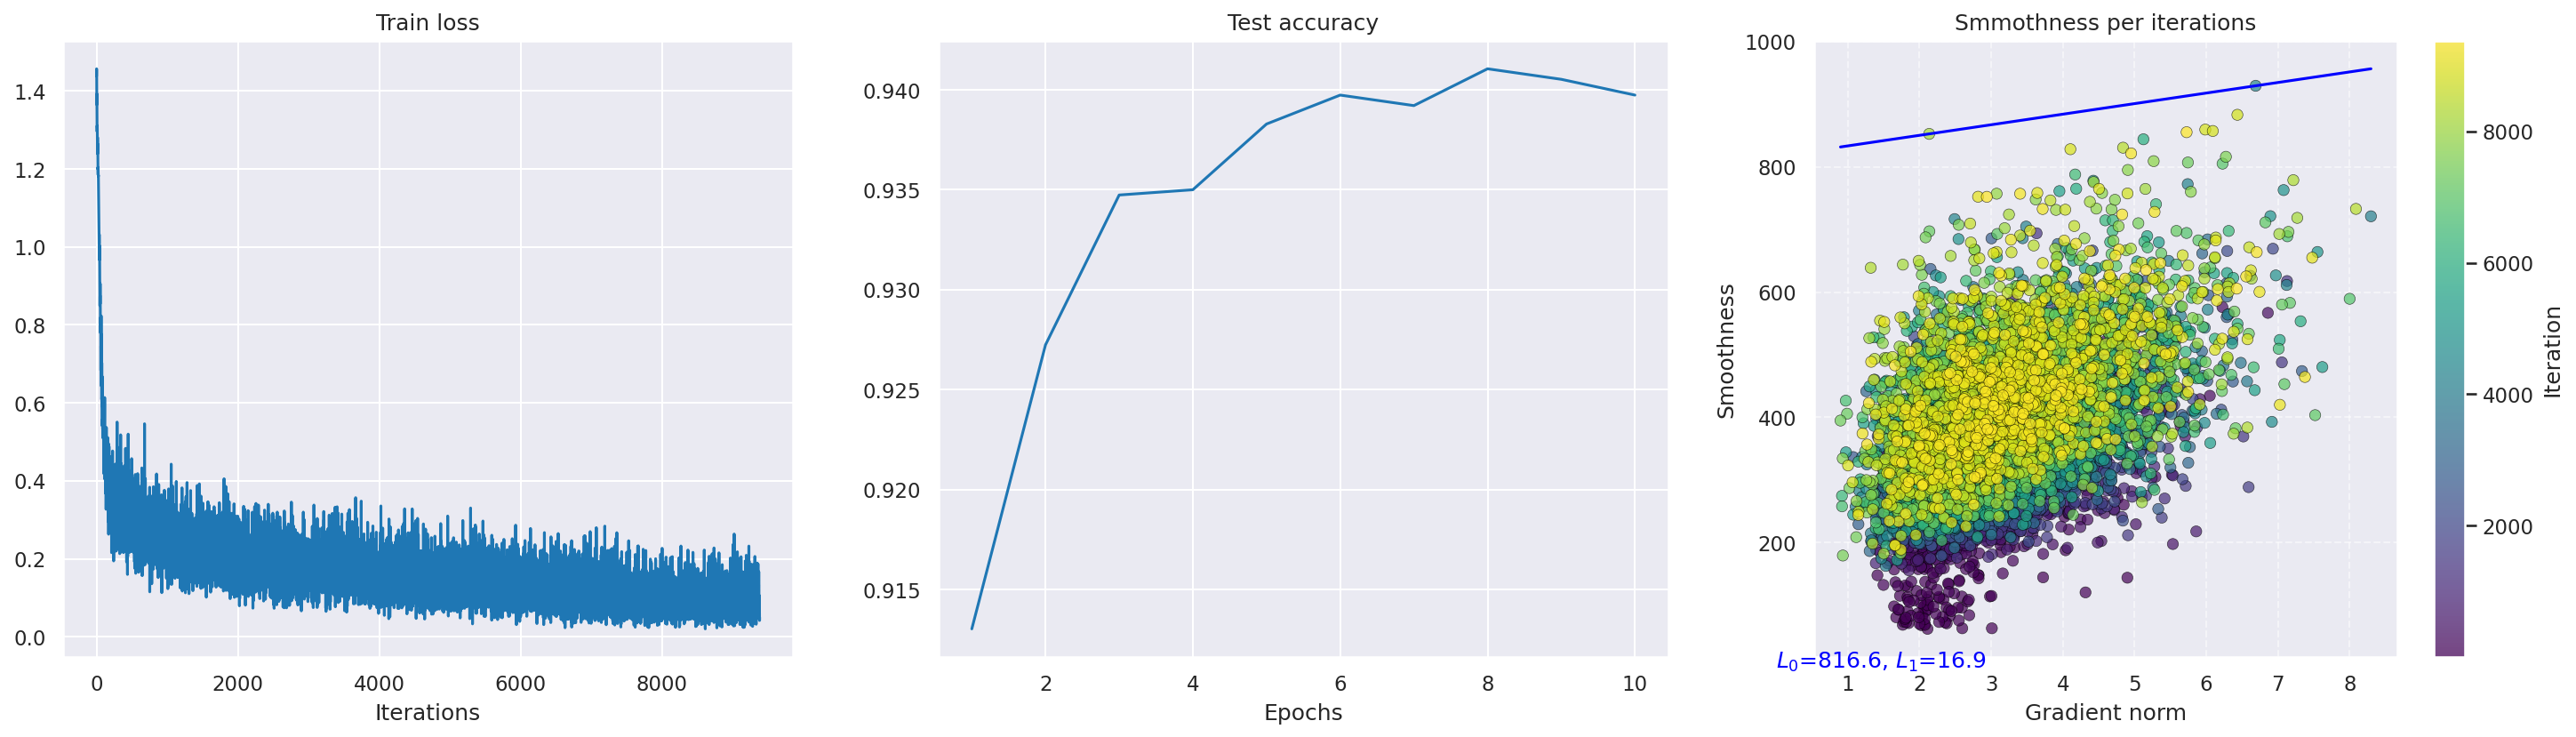

In [37]:
model = MiniBert(bert_model, hidden_dim, num_class).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = ExponentialLR(optimizer, gamma=0.98)
criterion = nn.CrossEntropyLoss()
verbose = True

epochs = 10

model, history = train_cycle(model,
                             optimizer,
                             scheduler,
                             criterion,
                             epochs,
                             device,
                             dataloader_train,
                             dataloader_test,
                             output_suptitle=suptitle,
                             verbose=True)


In [38]:
with open('./dump_result/mini_bert_smoothness.pickle', 'wb') as f:
    pickle.dump(history, f)
